# Task 4: Face, Voice, and Product Models

This notebook trains and evaluates the three Task 4 models, then checks the authorization chain against repository examples. Face evaluation holds out one expression at a time so augmented copies of a photo never cross a train/test boundary. Voice evaluation holds out complete phrases (or takes when repeated takes exist), keeping each recording's augmentations together. Product evaluation uses repeated five-fold `StratifiedGroupKFold` by `customer_id`, because social features repeat across a customer's transactions.

## 1. Label Unification Helper

Image data uses `nkuba` while audio data uses `junior` for the same person. `unify_member()` lowercases and strips labels, then maps `nkuba` to `junior` in memory. The image and audio CSVs and files are not changed; all model and CLI labels use david, junior, rolande, and sheila.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.model_utils import unify_member

label_examples = pd.DataFrame({
    "source_label": [" Nkuba ", "JUNIOR", " David ", "Rolande", "Sheila"],
    "unified_label": [unify_member(value) for value in [" Nkuba ", "JUNIOR", " David ", "Rolande", "Sheila"]],
})
display(label_examples)

,source_label,unified_label
0,Nkuba,junior
1,JUNIOR,junior
2,David,david
3,Rolande,rolande
4,Sheila,sheila


## 2. Face Model: Training and Evaluation

The face candidates are standardized logistic regression and random forest. Each fold trains on two expressions and tests the third, holding all nine versions of each held-out photo together. The open-set rule compares a new face to its nearest standardized training feature row; its threshold is selected from known expression-held-out and unknown member-held-out distances.

Face model comparison (pooled expression-held-out metrics):
                     accuracy  macro_f1  log_loss
logistic_regression  1.000000  1.000000  0.064560
random_forest        0.972222  0.972136  0.422205
Selected: logistic_regression; unknown threshold=19.7449; distance balanced accuracy=0.912


,model,split,accuracy,macro_f1,log_loss
0,logistic_regression,neutral,1.000000,1.000000,0.004569
1,logistic_regression,smiling,1.000000,1.000000,0.087386
2,logistic_regression,surprised,1.000000,1.000000,0.101724
3,logistic_regression,pooled,1.000000,1.000000,0.064560
4,random_forest,neutral,1.000000,1.000000,0.347324
5,random_forest,smiling,0.916667,0.914286,0.481026
6,random_forest,surprised,1.000000,1.000000,0.438264
7,random_forest,pooled,0.972222,0.972136,0.422205


Selected: logistic_regression | open-set: {'threshold': 19.74486251760379, 'known_distance_count': 108, 'unknown_distance_count': 108, 'balanced_accuracy': 0.912037037037037, 'known_mean_distance': 15.33697918514754, 'unknown_mean_distance': 26.26051506529961}


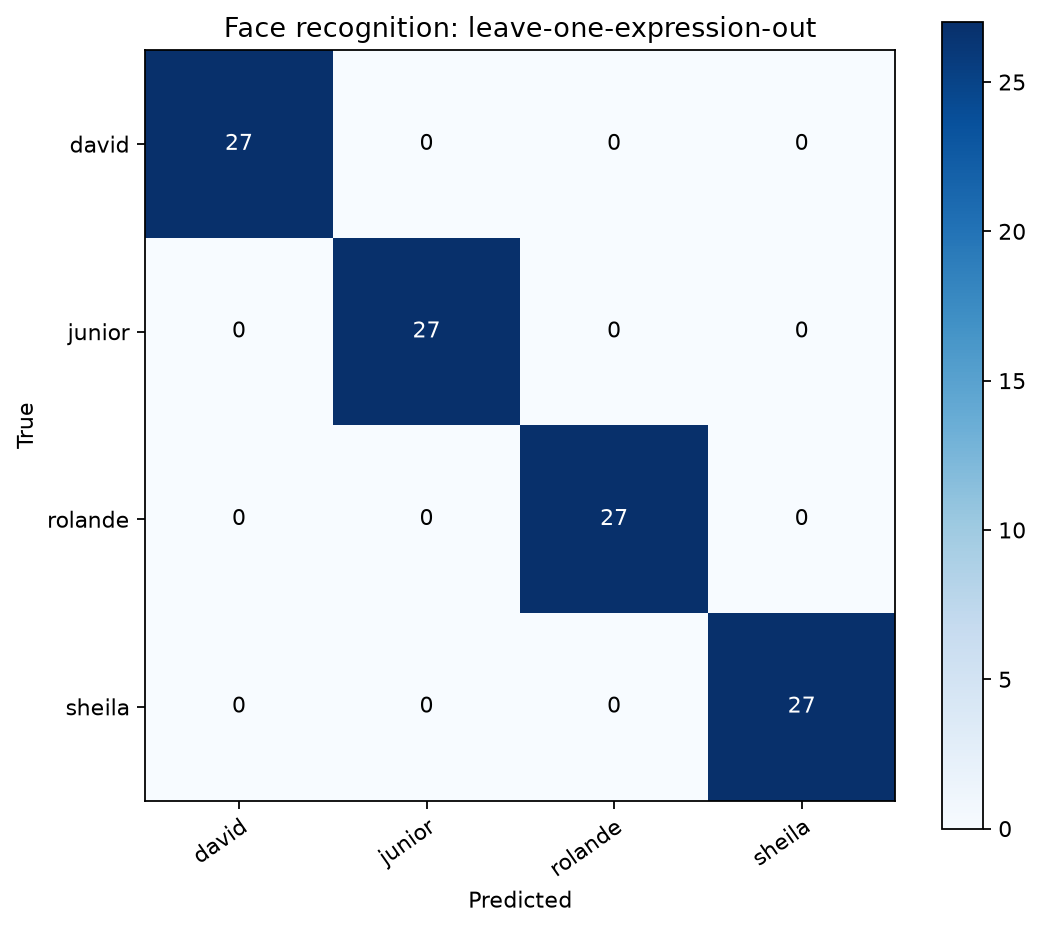

In [2]:
from src import face_model

face_model.train()
face_report = json.loads((ROOT / "models" / "face_metrics.json").read_text(encoding="utf-8"))
face_rows = []
for model_name, results in face_report["candidates"].items():
    for fold in results["folds"]:
        face_rows.append({"model": model_name, "split": fold["held_out_expression"], **{key: fold[key] for key in ["accuracy", "macro_f1", "log_loss"]}})
    face_rows.append({"model": model_name, "split": "pooled", **results["pooled"]})
display(pd.DataFrame(face_rows))
print("Selected:", face_report["selected_model"], "| open-set:", face_report["unknown_rule"])
display(Image(filename=str(ROOT / "figures" / "face_confusion_matrix.png")))

**Interpretation.** Face accuracy is high on these folds, but there are only three original photos per member. The nine rows per photo are correlated augmentations, not nine independent photographs. Background, lighting, and framing may therefore contribute strongly to recognition; this result is not broad biometric validation.

## 3. Voice Model: Training and Evaluation

The voice model compares Logistic Regression, RBF SVC, and Random Forest across three feature groups: all numeric audio features except metadata/duration, MFCC columns ending in `_mean`, and those MFCC means plus centroid, bandwidth, and rolloff mean/std columns. Each pair uses the existing leave-one-phrase-out split here because each member/phrase has one take; augmentations from a recording remain together. Select the pair by pooled macro-F1, breaking ties by lower log-loss. The verification threshold is calibrated from held-out genuine and impostor probabilities only; the Semana outsider row is never used to choose features, model, or threshold. Identification chance is 0.25 for four speakers.

C:\Users\user\AppData\Roaming\Python\Python314\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\user\AppData\Roaming\Python\Python314\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\Users\user\AppData\Roaming\Python\Python314\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\user\AppData\Roaming\Python\Python314\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\Users\user\AppData\Roaming\Python\Python314\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\user\AppData\Roaming\Python\Python314\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Voice feature/model ablation (pooled leave-one-phrase-out; chance accuracy=0.250):
              feature_set               model  feature_count  accuracy  macro_f1  log_loss  verification_balanced_accuracy
                      all logistic_regression             49     0.417     0.400     6.535                           0.677
                      all             svc_rbf             49     0.438     0.309     1.146                           0.712
                      all       random_forest             49     0.583     0.517     1.323                           0.715
               mfcc_means logistic_regression             13     0.396     0.415     2.788                           0.691
               mfcc_means             svc_rbf             13     0.312     0.250     1.199                           0.694
               mfcc_means       random_forest             13     0.604     0.536     1.085                           0.743
mfcc_means+spectral_means logistic_regression           

,feature_set,model,features,accuracy,macro_f1,log_loss,verification_balanced_accuracy,verification_threshold
0,all,logistic_regression,49,0.416667,0.400303,6.534911,0.677083,0.057255
1,all,svc_rbf,49,0.437500,0.308703,1.146055,0.711806,0.263635
2,all,random_forest,49,0.583333,0.516905,1.322736,0.715278,0.326667
3,mfcc_means,logistic_regression,13,0.395833,0.414980,2.787772,0.690972,0.111815
4,mfcc_means,svc_rbf,13,0.312500,0.250227,1.198721,0.694444,0.245489
5,mfcc_means,random_forest,13,0.604167,0.535920,1.085280,0.743056,0.281667
6,mfcc_means+spectral_means,logistic_regression,19,0.395833,0.382430,7.051481,0.677083,0.012029
7,mfcc_means+spectral_means,svc_rbf,19,0.437500,0.308703,1.146498,0.711806,0.268676
8,mfcc_means+spectral_means,random_forest,19,0.645833,0.586538,1.058867,0.777778,0.315000


,feature_set,model,accuracy,macro_f1,log_loss,held_out_group
0,all,logistic_regression,0.291667,0.291667,6.830071,confirm_transaction
1,all,logistic_regression,0.541667,0.474359,6.239750,yes_approve
2,all,svc_rbf,0.416667,0.297619,1.166510,confirm_transaction
3,all,svc_rbf,0.458333,0.319048,1.125601,yes_approve
4,all,random_forest,0.458333,0.401863,1.358382,confirm_transaction
5,all,random_forest,0.708333,0.606593,1.287091,yes_approve
6,mfcc_means,logistic_regression,0.375000,0.416667,2.460286,confirm_transaction
7,mfcc_means,logistic_regression,0.416667,0.414286,3.115259,yes_approve
8,mfcc_means,svc_rbf,0.375000,0.318564,1.212778,confirm_transaction
9,mfcc_means,svc_rbf,0.250000,0.166667,1.184663,yes_approve


Selected: mfcc_means+spectral_means + random_forest
Chance accuracy: 0.25
Verification: {'threshold': 0.315, 'balanced_accuracy': 0.7777777777777778, 'genuine_score_count': 48, 'impostor_score_count': 144}
Untuned Semana outsider demonstration:


,claimed_identity,probability,rejected
0,david,0.21,True
1,junior,0.28,True
2,rolande,0.44,False
3,sheila,0.07,True


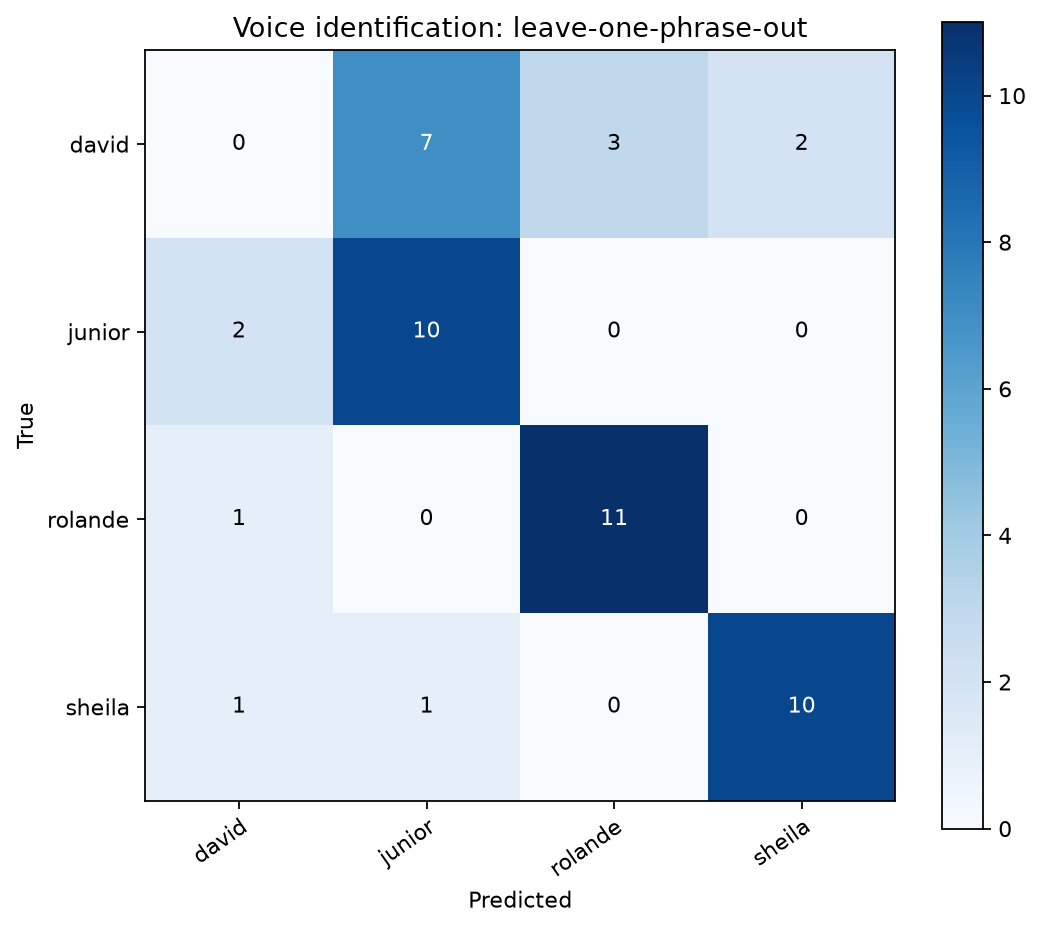

In [3]:
from src import voice_model

voice_model.train()
voice_report = json.loads((ROOT / "models" / "voice_metrics.json").read_text(encoding="utf-8"))
voice_ablation_rows = []
voice_fold_rows = []
for result in voice_report["feature_ablation"]:
    verification = result["verification"]
    voice_ablation_rows.append({
        "feature_set": result["feature_set"],
        "model": result["model"],
        "features": result["feature_count"],
        **result["pooled"],
        "verification_balanced_accuracy": verification["balanced_accuracy"],
        "verification_threshold": verification["threshold"],
    })
    for fold in result["folds"]:
        voice_fold_rows.append({
            "feature_set": result["feature_set"],
            "model": result["model"],
            **fold,
        })
display(pd.DataFrame(voice_ablation_rows).drop(columns=["held_out_group"], errors="ignore"))
display(pd.DataFrame(voice_fold_rows))
print("Selected:", voice_report["selected_feature_set"], "+", voice_report["selected_model"])
print("Chance accuracy:", voice_report["chance_accuracy"])
print("Verification:", voice_report["verification"])
print("Untuned Semana outsider demonstration:")
display(pd.DataFrame(voice_report["outsider_demo_not_used_for_tuning"]))
display(Image(filename=str(ROOT / "figures" / "voice_confusion_matrix.png")))

**Interpretation.** The selected 19-feature `mfcc_means+spectral_means` set with Random Forest achieved accuracy 0.646, macro-F1 0.587, and log-loss 1.059. Verification threshold is 0.315 and balanced accuracy is 0.778, so the script still warns that more takes are needed. The feature set was chosen by cross-validation on a small dataset, so these numbers may be slightly optimistic. The reserved Semana row is denied for david, junior, and sheila, but accepted for rolande; this outsider false-accept problem is not solved.

## 4. Product Model: Training and Evaluation

The product model predicts `product_category` before purchase. It excludes customer/transaction IDs, purchase date, purchase amount, rating, rating-missing flag, and amount tier. Numeric data is median-imputed and standardized; categorical data is imputed with `none` and one-hot encoded. Repeated five-fold `StratifiedGroupKFold` keeps each customer's transactions on one side of each fold. The model comparison includes a prior baseline, logistic regression, random forest, and a small XGBoost model. The additional post-purchase ablation is diagnostic only and is **NOT allowed for a real prediction**.

Product grouped-CV results (mean +/- std across 25 folds):
                           accuracy_mean  macro_f1_mean  log_loss_mean  accuracy_std  macro_f1_std  log_loss_std
model                                                                                                           
baseline_prior                     0.217          0.071          1.601         0.011         0.003         0.005
logistic_regression                0.238          0.226          2.122         0.082         0.076         0.462
logistic_regression_c0.05          0.239          0.223          1.629         0.088         0.081         0.129
random_forest                      0.208          0.180          1.694         0.105         0.095         0.134
xgboost                            0.217          0.202          2.261         0.077         0.065         0.327
Baseline prior next to selected model:
                           accuracy_mean  macro_f1_mean  log_loss_mean  accuracy_std  macro_f1_std  log_loss_st

,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,log_loss_mean,log_loss_std
model,,,,,,
baseline_prior,0.217130,0.011030,0.071333,0.002928,1.601138,0.005470
logistic_regression,0.237649,0.081774,0.225693,0.075546,2.122147,0.461683
logistic_regression_c0.05,0.238965,0.087764,0.222796,0.081431,1.629498,0.129213
random_forest,0.208368,0.104933,0.179637,0.094710,1.693883,0.133991
xgboost,0.216852,0.077197,0.201900,0.064522,2.261428,0.327001


Selected: logistic_regression_c0.05
Out-of-fold metrics: {'accuracy': 0.2564102564102564, 'macro_f1': 0.25225389419455174, 'log_loss': 1.6168722204099988}
Ablation with post-purchase columns (NOT allowed for a real prediction):
{'features_added': ['purchase_amount', 'customer_rating', 'rating_missing', 'amount_tier'], 'model': 'logistic_regression_c0.05', 'mean': {'accuracy': 0.24751014492753623, 'macro_f1': 0.22836121656121655, 'log_loss': 1.6630332381909017}, 'std': {'accuracy': 0.08198074717671494, 'macro_f1': 0.07580364475964284, 'log_loss': 0.14148220204905798}}


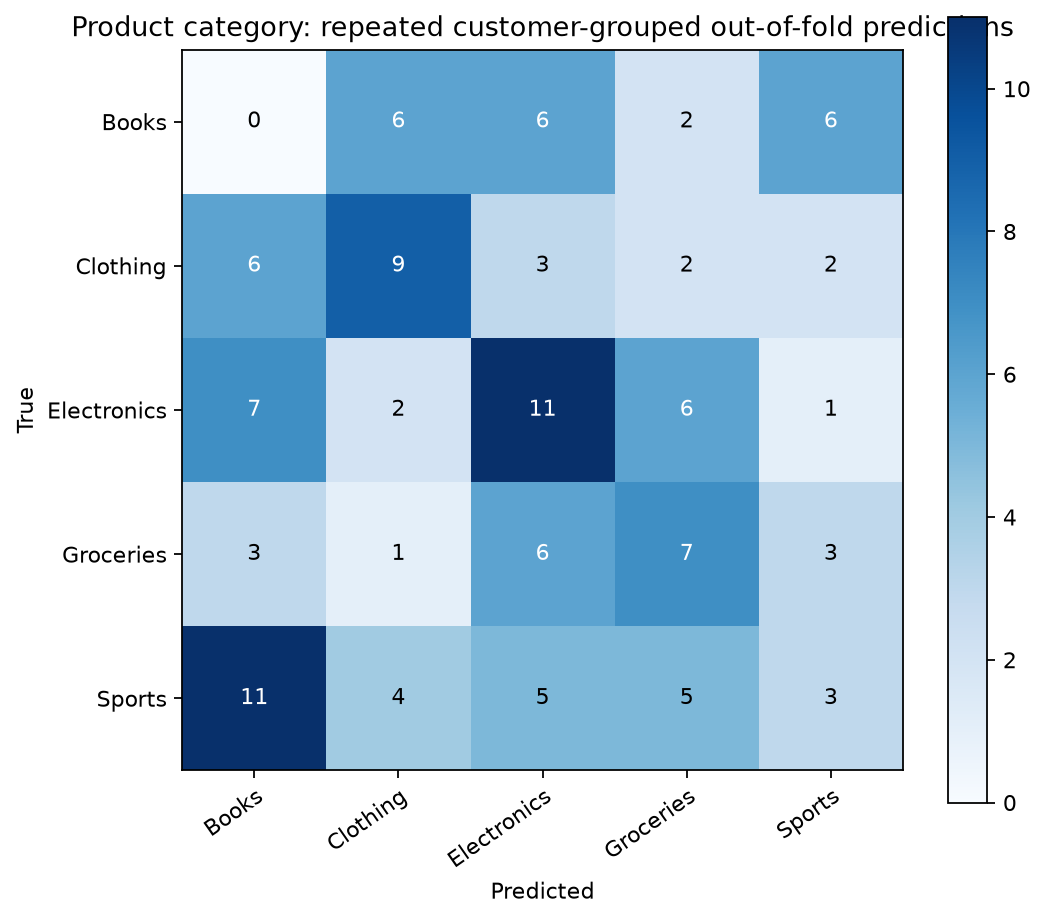

In [4]:
from src import product_model

product_model.train()
product_report = json.loads((ROOT / "models" / "product_metrics.json").read_text(encoding="utf-8"))
product_rows = []
for model_name, results in product_report["comparison"].items():
    row = {"model": model_name}
    for metric in ["accuracy", "macro_f1", "log_loss"]:
        row[f"{metric}_mean"] = results["mean"][metric]
        row[f"{metric}_std"] = results["std"][metric]
    product_rows.append(row)
display(pd.DataFrame(product_rows).set_index("model"))
print("Selected:", product_report["selected_model"])
print("Out-of-fold metrics:", product_report["selected_out_of_fold_metrics"])
print("Ablation with post-purchase columns (NOT allowed for a real prediction):")
print(product_report["ablation_not_allowed_for_real_prediction"])
display(Image(filename=str(ROOT / "figures" / "product_confusion_matrix.png")))

**Interpretation.** The best model by macro-F1 (standard LogisticRegression) was not used because its mean log-loss of 2.122 was more than 0.05 above the class-prior baseline of 1.601. LogisticRegression(C=0.05) was selected; its mean grouped-CV accuracy was 0.239 ± 0.088, macro-F1 0.223 ± 0.081, and log-loss 1.629 ± 0.129 over 25 folds, within 0.05 of baseline. The baseline achieved accuracy 0.217, macro-F1 0.071, and log-loss 1.601. The selected model is only slightly above the baseline, consistent with weak signal; its accuracy gain is 0.022. The post-purchase ablation is not deployable and does not replace the restricted pre-purchase result.

## 5. Multimodal Decision Logic and Demo Chain

The sequence is face image → identity → voice verification for the **same claimed identity** → product recommendation. Failure to detect/accept the face, verify the claimed voice, or run a required step means **ACCESS DENIED**. Product recommendation is never called before both biometric checks pass. This repository-file preview is a wiring check, not an accuracy test: it reuses an existing image and a precomputed audio feature row rather than capturing a new synchronized transaction.

In [5]:
from src import voice_model

chain = {"face": None, "voice": None, "product": None, "status": "ACCESS DENIED"}
try:
    face_result = face_model.predict_image(ROOT / "data" / "images" / "david_neutral.jpg")
    chain["face"] = face_result
    if face_result["authorized"] and face_result["user"] is not None:
        claimed_identity = face_result["user"]
        audio_rows = pd.read_csv(ROOT / "task3_audio" / "audio_features.csv")
        audio_rows = audio_rows.loc[
            (audio_rows["member"].map(unify_member) == claimed_identity)
            & (audio_rows["augmentation"] == "original")
        ]
        if not audio_rows.empty:
            voice_result = voice_model.predict_features(audio_rows.iloc[[0]], claimed_user=claimed_identity)
            chain["voice"] = voice_result
            if voice_result["authorized"]:
                chain["product"] = product_model.recommend(claimed_identity, top_k=3)
                chain["status"] = "ACCESS GRANTED"
except Exception as error:
    chain["error"] = f"{type(error).__name__}: {error}"

print(json.dumps(chain, indent=2))

{
  "face": {
    "user": "david",
    "best_guess": "david",
    "confidence": 0.9997066297511771,
    "distance": 0.0,
    "authorized": true,
    "face_detected": true
  },
  "voice": {
    "claimed_user": "david",
    "best_guess": "david",
    "confidence": 0.92,
    "authorized": true,
    "probabilities": {
      "david": 0.92,
      "junior": 0.06666666666666667,
      "rolande": 0.01,
      "sheila": 0.0033333333333333335
    }
  },
  "product": {
    "member": "david",
    "simulated_customer_id": 187,
    "prediction": "Books",
    "top_k": [
      {
        "product_category": "Books",
        "probability": 0.30155006944425466
      },
      {
        "product_category": "Sports",
        "probability": 0.2956195001890171
      },
      {
        "product_category": "Clothing",
        "probability": 0.22660300496326058
      }
    ],
    "simulation": true
  },
  "status": "ACCESS GRANTED"
}


## 6. Preview: Outsider Voice Test Against All Identities

This one outsider feature row is a demonstration sample only; it is not used to fit the voice model or tune its threshold. Each possible face-claimed identity is checked independently by the verification helper.

In [6]:
outsider_row = pd.read_csv(ROOT / "task3_audio" / "unauthorized_audio_features.csv")
outsider_results = []
for claimed_identity in ["david", "junior", "rolande", "sheila"]:
    result = voice_model.predict_features(outsider_row, claimed_user=claimed_identity)
    outsider_results.append({
        "claimed_identity": claimed_identity,
        "claimed_probability": result["confidence"],
        "threshold": voice_report["verification"]["threshold"],
        "decision": "ACCESS GRANTED" if result["authorized"] else "ACCESS DENIED",
    })
display(pd.DataFrame(outsider_results))

,claimed_identity,claimed_probability,threshold,decision
0,david,0.21,0.315,ACCESS DENIED
1,junior,0.28,0.315,ACCESS DENIED
2,rolande,0.44,0.315,ACCESS GRANTED
3,sheila,0.07,0.315,ACCESS DENIED
